# Clase 13 — Del modelo a la decisión: el umbral económico

**Laboratorio de Modelo Analítico para la Toma de Decisiones** · ISTEA 89354 · 2026-2C
Material de lectura · viernes 13 de noviembre de 2026

---

### Cómo leer esto

Este cuaderno reemplaza la clase, así que está escrito para leerse solo: el texto explica lo
que normalmente diría en voz alta. **Léanlo corrido una vez sin correr nada**, para quedarse
con la idea. Después vuelvan y corran las celdas, que es donde aparecen los números.

En el **taller del viernes 20** aplicamos esto sobre el dataset de cada equipo, con tiempo y
conmigo al lado. Lleguen con esto leído y el taller rinde el triple.

Es la última pieza del trabajo final: la **sección 7**.

---

## El problema

Terminamos la clase 12 con un modelo que le pone una probabilidad de abandono a cada cliente.
Eso todavía no es una decisión. Para actuar hay que contestar: **¿a quiénes contactamos?**

La respuesta fácil sería «a los que el modelo clasifica como que se van». Pero esa
clasificación usa un umbral de 0,5 que viene de fábrica en la librería y que **nadie eligió
para este problema**. No conoce el negocio, no sabe cuánto cuesta una llamada ni cuánto vale
un cliente.

Hoy reemplazamos ese 0,5 por un número que sale de una cuenta.

## 1 · Los errores no cuestan lo mismo

Cuando decidimos contactar o no contactar a un cliente que se va o no se va, hay cuatro
casos posibles:

| | **Se iba a ir** | **Se iba a quedar** |
|---|---|---|
| **Lo contacto** | Acierto útil: gasté el contacto y quizás lo retuve | Error barato: gasté un contacto al pedo |
| **No lo contacto** | **Error caro: perdí el cliente** | Acierto gratis: no gasté nada |

Los dos errores están en la diagonal, y **son de tamaños completamente distintos**. Molestar
a alguien que se iba a quedar cuesta una llamada. Dejar ir a alguien que se iba cuesta todo
lo que ese cliente iba a facturar.

Ese desbalance es exactamente lo que el acierto ignora. El acierto cuenta errores, no los
pesa: para él los dos casos de la diagonal valen igual. Por eso maximizar el acierto no
maximiza la plata, y por eso el 0,5 está mal casi siempre.

## 2 · Los tres parámetros

Para pesar los errores hacen falta tres números que **no están en el archivo**. Salen del
anexo de supuestos económicos, que fija la cátedra para que los resultados sean comparables
entre equipos.

- **C — costo de contactar.** Lo que cuesta un contacto: una llamada, un cupón, una visita.
- **V — valor de retener.** Lo que se gana si el cliente se queda un período más.
- **E — efectividad.** Qué proporción de los contactados efectivamente se queda. Nunca es 1:
  contactar no garantiza retener.

Para ElecCommSphere usamos: **C = $4.000**, **V = $85.000**, **E = 25 %**.

> **Busquen la fila de su dataset en el anexo.** Si en la columna del valor dice «del
> archivo», es porque V se calcula cliente por cliente con sus propios datos, y entonces el
> umbral también les va a variar por cliente. Eso no es una complicación: es una versión
> mejor del análisis, y está explicado al final.

## 3 · Armamos el modelo de la clase 12

Nada nuevo acá: es el mismo código, para tener las probabilidades con las que vamos a decidir.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
AZUL, GRIS, ROJO, VERDE = "#0A2FF1", "#6E7280", "#B4341F", "#1E7A46"

tx  = pd.read_csv("eleccommsphere_transacciones.csv", parse_dates=["fecha"])
cli = pd.read_csv("eleccommsphere_clientes.csv", parse_dates=["fecha_alta"])
t = tx.drop_duplicates()
t = t[t["id_cliente"].isin(cli["id_cliente"])]
t["categoria"] = (t["categoria"].str.strip().str.lower()
                    .str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("utf-8"))
t = t[t["monto"].notna() & (t["monto"] > 0)]
t = t[t["monto"] <= t["monto"].quantile(0.999)]

CORTE = pd.Timestamp("2026-03-31")
obs, post = t[t["fecha"] <= CORTE], t[t["fecha"] > CORTE]
g = obs.groupby("id_cliente")
X = pd.DataFrame({
    "recencia":   (CORTE - g["fecha"].max()).dt.days,
    "frecuencia": g.size(),
    "monto":      g["monto"].sum(),
    "ticket":     g["monto"].mean(),
    "antiguedad": (CORTE - g["fecha"].min()).dt.days,
    "categorias": g["categoria"].nunique(),
    "canales":    g["canal"].nunique(),
    "tasa_dev":   g["devuelto"].mean(),
})
X["intensidad"] = X["frecuencia"] / X["antiguedad"].clip(lower=1)
y = pd.Series((~X.index.isin(post["id_cliente"])).astype(int), index=X.index, name="churn")

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
modelo = Pipeline([("escalar", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)

prob = modelo.predict_proba(Xte)[:, 1]
real = yte.values
print(f"{len(prob)} clientes de prueba · abandono real {real.mean():.1%}")

920 clientes de prueba · abandono real 45.5%


# **El modelo les dice quién es más riesgoso. El umbral no sale de ningún modelo: sale de una división entre lo que cuesta actuar y lo que se gana.**

## 4 · El umbral teórico

Antes de medir nada, se puede razonar. Pensemos en **un** cliente al que le asignamos una
probabilidad **p** de irse, y preguntémonos si conviene contactarlo.

**Si lo contacto**, pago C seguro. Y gano algo solo en un caso: que el cliente efectivamente
se fuera a ir (probabilidad p) **y** que el contacto funcione (probabilidad E). O sea que el
beneficio esperado es `p × E × V`.

**Si no lo contacto**, no pago ni gano nada.

Entonces conviene contactarlo cuando el beneficio esperado supera el costo:

```
p × E × V  >  C
```

Despejando p queda el umbral:

```
umbral = C / (E × V)
```

Con nuestros números: **4.000 / (0,25 × 85.000) = 0,188**.

Fíjense qué dice la fórmula, que es más interesante que el número:

- **Si contactar se abarata**, C baja y el umbral baja: conviene contactar a más gente.
- **Si el cliente vale más**, V sube y el umbral baja: también conviene ampliar.
- **Si la acción de retención funciona mejor**, E sube y el umbral baja.

En los tres casos la conclusión es la misma y es contraintuitiva: **casi todo lo que mejora
el negocio empuja a contactar a MÁS gente, no a menos**. El 0,5 de fábrica es un umbral
altísimo para este problema.

In [ ]:
COSTO_CONTACTO  = 4_000      # C — lo que cuesta contactar a un cliente
VALOR_RETENCION = 85_000     # V — lo que se gana si se queda un período más
EFECTIVIDAD     = 0.25       # E — proporción de contactados que efectivamente se queda

umbral_teorico = COSTO_CONTACTO / (EFECTIVIDAD * VALOR_RETENCION)
print(f"umbral teórico = {COSTO_CONTACTO:,} / ({EFECTIVIDAD} × {VALOR_RETENCION:,}) "
      f"= {umbral_teorico:.3f}")
print(f"\nSe contacta a todo cliente con probabilidad de abandono mayor a {umbral_teorico:.1%}.")

umbral teórico = 4,000 / (0.25 × 85,000) = 0.188

Se contacta a todo cliente con probabilidad de abandono mayor a 18.8%.


# **Un modelo no vale nada en abstracto. Vale lo que vale la decisión que permite tomar. Y eso lo decide el costo de actuar, no el AUC.”**

## 5 · Ahora medimos

El umbral teórico sale de razonar sobre un cliente promedio. Veamos qué pasa de verdad con
los 920 clientes de prueba, barriendo todos los umbrales posibles y calculando el resultado
en plata de cada uno.

La cuenta por umbral es simple: contactamos a los que superan el umbral, pagamos C por cada
uno, y recuperamos E × V por cada contactado que efectivamente se iba a ir.

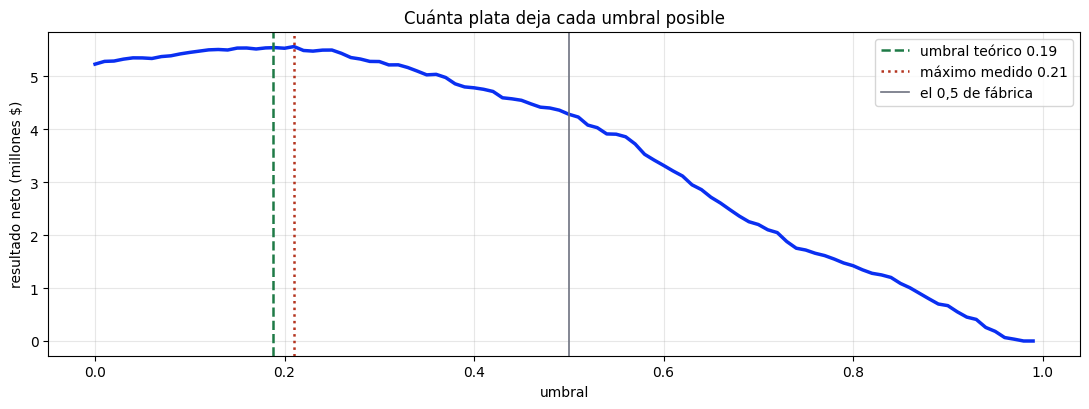

 umbral  contactados  fugas marcadas   costo  beneficio      neto
    0.0          920             419 3680000  8903750.0 5223750.0
    0.1          838             414 3352000  8797500.0 5445500.0
    0.2          760             403 3040000  8563750.0 5523750.0
    0.3          658             372 2632000  7905000.0 5273000.0
    0.5          386             274 1544000  5822500.0 4278500.0
    0.7          173             136  692000  2890000.0 2198000.0
    0.9           51              41  204000   871250.0  667250.0


In [ ]:
def resultado(u):
    marca       = prob >= u
    contactados = int(marca.sum())
    fugas       = int((marca & (real == 1)).sum())
    costo       = contactados * COSTO_CONTACTO
    beneficio   = fugas * EFECTIVIDAD * VALOR_RETENCION
    return {"umbral": round(u, 2), "contactados": contactados, "fugas marcadas": fugas,
            "costo": costo, "beneficio": beneficio, "neto": beneficio - costo}

barrido = pd.DataFrame([resultado(u) for u in np.arange(0, 1.0, 0.01)])
mejor   = barrido.loc[barrido["neto"].idxmax()]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(barrido["umbral"], barrido["neto"] / 1e6, color=AZUL, lw=2.5)
ax.axvline(umbral_teorico, ls="--", color=VERDE, lw=1.8,
           label=f"umbral teórico {umbral_teorico:.2f}")
ax.axvline(mejor["umbral"], ls=":", color=ROJO, lw=1.8,
           label=f"máximo medido {mejor['umbral']:.2f}")
ax.axvline(0.5, ls="-", color=GRIS, lw=1.2, label="el 0,5 de fábrica")
ax.set_xlabel("umbral"); ax.set_ylabel("resultado neto (millones $)")
ax.set_title("Cuánta plata deja cada umbral posible"); ax.legend()
plt.tight_layout(); plt.show()

print(barrido[barrido["umbral"].isin([0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9])].to_string(index=False))

### Tres cosas que leer en ese gráfico

**Primero: la teoría funcionó.** El umbral teórico dio 0,19 y el máximo medido está en 0,21.
Casi pegados. La fórmula de una línea predice bien dónde está el óptimo, y eso vale porque en
la práctica no siempre se puede barrer: si tuvieran que decidir sin los datos de resultado,
la fórmula alcanza.

**Segundo: el 0,5 de fábrica es caro.** Con el umbral óptimo el resultado neto es de unos
$5,56 millones; con 0,5 es de $4,28 millones. **Usar el valor por defecto cuesta alrededor de
1,28 millones de pesos** — no por un error de modelado, sino por no haber elegido un número.

**Tercero, y es lo más útil: la curva es una meseta.** Entre 0,02 y 0,28 el resultado se
mueve muy poco — cualquier umbral de ese rango queda a menos del 5 % del máximo. Eso significa que **no hace falta acertar el umbral exacto**: cualquier valor
razonable en ese rango da prácticamente lo mismo. Es una buena noticia y conviene decirla en
el informe, porque evita discusiones estériles sobre si el corte va en 0,18 o en 0,22. Lo que
sí importa es no estar en 0,5.

In [ ]:
neto_opt   = mejor["neto"]
neto_medio = barrido.loc[barrido["umbral"] == 0.50, "neto"].iloc[0]
meseta     = barrido[barrido["neto"] >= neto_opt * 0.95]

print(f"Umbral óptimo   : {mejor['umbral']:.2f}  →  contacta a {int(mejor['contactados'])} "
      f"y deja ${neto_opt:,.0f}")
print(f"Umbral de fábrica: 0.50  →  contacta a {int(barrido.loc[barrido.umbral==0.5,'contactados'].iloc[0])} "
      f"y deja ${neto_medio:,.0f}")
print(f"\nLo que cuesta no elegir: ${neto_opt - neto_medio:,.0f}")
print(f"Meseta al 95 % del máximo: de {meseta['umbral'].min():.2f} a {meseta['umbral'].max():.2f}")

Umbral óptimo   : 0.21  →  contacta a 752 y deja $5,555,750
Umbral de fábrica: 0.50  →  contacta a 386 y deja $4,278,500

Lo que cuesta no elegir: $1,277,250
Meseta al 95 % del máximo: de 0.02 a 0.28


## 6 · La pregunta incómoda: ¿sirvió de algo el modelo?

Miren el extremo izquierdo del gráfico. Con umbral 0 contactamos a **todos** los clientes,
sin modelo, sin segmentación, sin nada. Comparemos ese resultado con el óptimo.

In [ ]:
sin_modelo = barrido.loc[barrido["umbral"] == 0.0, "neto"].iloc[0]
print(f"Contactando a TODOS (sin modelo): ${sin_modelo:,.0f}")
print(f"Con el modelo y el umbral óptimo: ${neto_opt:,.0f}")
print(f"\nLo que aporta el modelo: ${neto_opt - sin_modelo:,.0f} "
      f"({(neto_opt - sin_modelo) / sin_modelo:.1%} más)")

Contactando a TODOS (sin modelo): $5,223,750
Con el modelo y el umbral óptimo: $5,555,750

Lo que aporta el modelo: $332,000 (6.4% más)


**El modelo aporta un 6 %.** Después de tres clases construyéndolo.

No es un error ni una decepción: es una propiedad del problema. Con un contacto que cuesta
$4.000 y un cliente que vale $85.000, contactar está tan barato que **conviene contactar a
casi todo el mundo igual**, y ahí el modelo tiene poco para agregar. El modelo sirve para
decidir a quién dejar afuera, y acá casi no hay a quién dejar afuera.

La pregunta que sigue es la buena: **¿de qué depende que el modelo valga mucho o poco?**

## 7 · El valor del modelo depende del costo

Repitamos todo el análisis cambiando el costo de contactar, y midamos cuánto vale tener el
modelo en cada escenario. «Cuánto vale» es la diferencia entre decidir con el modelo y
contactar a todos.

# **El valor de un modelo no está en el modelo. Está en cuánto cuesta la decisión que ayuda a tomar. Si actuar es barato, actuá sobre todos y ahorrate el modelo. Si actuar es caro, el modelo es lo que evita que tires la plata.**

El eje de abajo no son datos: son decisiones. Cada punto es un ‘yo llamaría a los que tienen más de tanto por ciento de riesgo’. Y la altura te dice cuánto te habría dejado esa decisión.

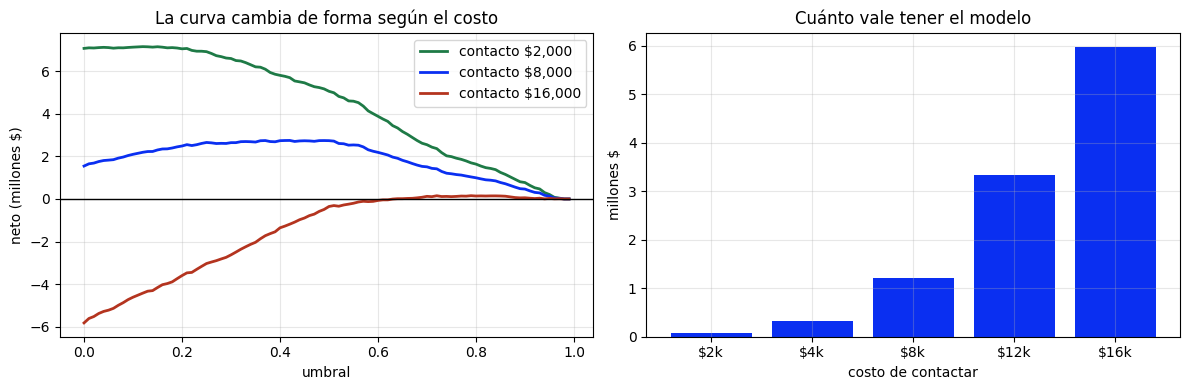

,costo contacto,umbral teórico,umbral óptimo,a cuántos contacta,neto con modelo,neto contactando a todos,valor del modelo
0,2000,0.09,0.12,826,7145500,7063750,81750
1,4000,0.19,0.21,752,5555750,5223750,332000
2,8000,0.38,0.42,491,2744500,1543750,1200750
3,12000,0.56,0.51,378,1201500,-2136250,3337750
4,16000,0.75,0.79,110,152500,-5816250,5968750


In [ ]:
def neto_con(u, costo):
    marca = prob >= u
    return (marca & (real == 1)).sum() * EFECTIVIDAD * VALOR_RETENCION - marca.sum() * costo

us = np.arange(0, 1.0, 0.01)
filas = []
for costo in [2_000, 4_000, 8_000, 12_000, 16_000]:
    netos = [neto_con(u, costo) for u in us]
    i = int(np.argmax(netos))
    filas.append({
        "costo contacto": costo,
        "umbral teórico": round(costo / (EFECTIVIDAD * VALOR_RETENCION), 2),
        "umbral óptimo":  round(us[i], 2),
        "a cuántos contacta": int((prob >= us[i]).sum()),
        "neto con modelo": int(netos[i]),
        "neto contactando a todos": int(neto_con(0, costo)),
        "valor del modelo": int(netos[i] - neto_con(0, costo)),
    })
sens = pd.DataFrame(filas)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for costo, col in zip([2_000, 8_000, 16_000], [VERDE, AZUL, ROJO]):
    a1.plot(us, [neto_con(u, costo) / 1e6 for u in us], color=col, lw=2,
            label=f"contacto ${costo:,}")
a1.axhline(0, color="k", lw=1); a1.set_xlabel("umbral")
a1.set_ylabel("neto (millones $)"); a1.legend()
a1.set_title("La curva cambia de forma según el costo")

a2.bar([f"${c//1000}k" for c in sens["costo contacto"]],
       sens["valor del modelo"] / 1e6, color=AZUL)
a2.set_xlabel("costo de contactar"); a2.set_ylabel("millones $")
a2.set_title("Cuánto vale tener el modelo")
plt.tight_layout(); plt.show()

sens

### Acá está la lección de la clase

Miren la última columna. El mismo modelo, con el mismo AUC de 0,772, vale:

- **$332.000** si contactar cuesta $4.000
- **$5.968.750** si contactar cuesta $16.000

Dieciocho veces más, sin haber tocado una línea del modelo. Lo único que cambió es el precio
de equivocarse.

**Un modelo no vale nada en abstracto. Vale lo que vale la decisión que permite tomar.** Si
actuar es barato, actuá sobre todos y ahorrate el modelo. Si actuar es caro, el modelo es lo
que evita que tires la plata.

Esto también explica por qué dos empresas con el mismo problema y el mismo modelo pueden
tomar decisiones opuestas sobre si vale la pena construirlo. Y es la razón por la que, antes
de empezar un proyecto de datos, conviene preguntar cuánto cuesta la acción: a veces la
respuesta correcta es que no hace falta ningún modelo.

> **Un detalle para el informe.** Si el costo de contactar llegara a igualar `E × V` —en
> nuestro caso $21.250— el umbral teórico daría 1,00 y no convendría contactar a nadie, ni
> siquiera a alguien que se va con certeza. Ese es el límite natural del problema: cuando la
> acción cuesta más de lo que puede recuperar, la decisión correcta es no actuar.

---
# Parte B · Sobre su dataset

Tres pasos. Si llegan al taller del 20 con esto corrido, lo usamos para discutir en vez de
para programar.

In [ ]:
# ── 1. Los parámetros de SU fila del anexo ──────────────────────────────
C_PROPIO = 4_000       # ← costo de contactar
V_PROPIO = 85_000      # ← valor de retener  (si dice «del archivo», ver abajo)
E_PROPIA = 0.25        # ← efectividad

# ── 2. Sus probabilidades, de la clase 12 ───────────────────────────────
# mis_prob = pd.read_csv("mis_clientes_con_riesgo.csv", index_col=0)
# p_mio, real_mio = mis_prob["prob"].values, mis_prob["se_fue"].values
p_mio, real_mio = prob, real          # ← reemplazar por lo suyo

u_teorico = C_PROPIO / (E_PROPIA * V_PROPIO)
print(f"Su umbral teórico: {u_teorico:.3f}")

if u_teorico >= 1:
    print("  → Mayor a 1: con estos parámetros no conviene contactar a nadie.")
    print("    Revisen la fila del anexo antes de seguir.")
else:
    print(f"  → Contactar a todo cliente con probabilidad mayor a {u_teorico:.1%}")
    print(f"    En su base eso son {(p_mio >= u_teorico).sum()} clientes de {len(p_mio)}.")

Su umbral teórico: 0.188
  → Contactar a todo cliente con probabilidad mayor a 18.8%
    En su base eso son 775 clientes de 920.


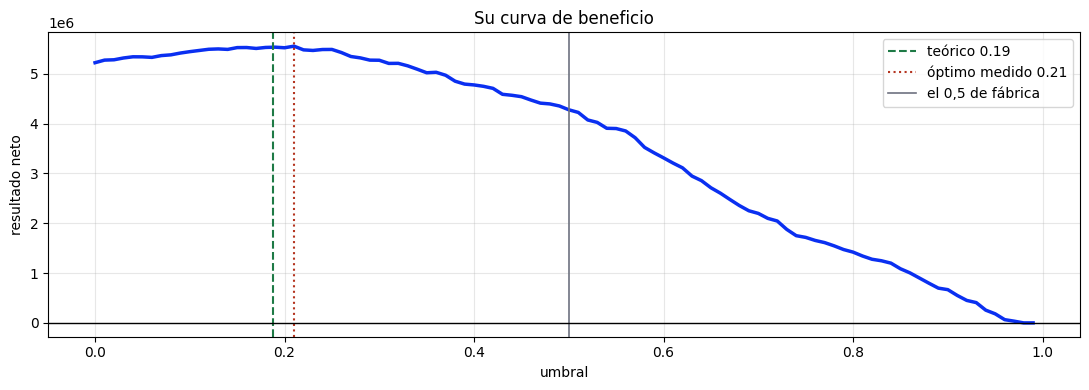

Umbral óptimo        : 0.21 → contacta a 752 clientes
Neto en el óptimo    : 5,555,750
Neto con el 0,5      : 4,278,500   (diferencia: 1,277,250)
Neto contactando a todos: 5,223,750   → el modelo aporta 332,000
Meseta al 95 %       : de 0.02 a 0.28


In [ ]:
# ── 3. El barrido sobre sus datos ───────────────────────────────────────
def neto_mio(u):
    marca = p_mio >= u
    return (marca & (real_mio == 1)).sum() * E_PROPIA * V_PROPIO - marca.sum() * C_PROPIO

us = np.arange(0, 1.0, 0.01)
netos = np.array([neto_mio(u) for u in us])
i_opt = int(netos.argmax())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(us, netos, color=AZUL, lw=2.5)
ax.axvline(u_teorico, ls="--", color=VERDE, label=f"teórico {u_teorico:.2f}")
ax.axvline(us[i_opt], ls=":", color=ROJO, label=f"óptimo medido {us[i_opt]:.2f}")
ax.axvline(0.5, color=GRIS, lw=1.2, label="el 0,5 de fábrica")
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("umbral"); ax.set_ylabel("resultado neto"); ax.legend()
ax.set_title("Su curva de beneficio")
plt.tight_layout(); plt.show()

meseta_mia = us[netos >= netos[i_opt] * 0.95]
print(f"Umbral óptimo        : {us[i_opt]:.2f} → contacta a {(p_mio >= us[i_opt]).sum()} clientes")
print(f"Neto en el óptimo    : {netos[i_opt]:,.0f}")
print(f"Neto con el 0,5      : {neto_mio(0.5):,.0f}   (diferencia: {netos[i_opt]-neto_mio(0.5):,.0f})")
print(f"Neto contactando a todos: {neto_mio(0):,.0f}   → el modelo aporta {netos[i_opt]-neto_mio(0):,.0f}")
print(f"Meseta al 95 %       : de {meseta_mia.min():.2f} a {meseta_mia.max():.2f}")

> **Si su dataset dice «del archivo» en la columna del valor** —Online Retail II, Complete
> Journey, Olist y Superstore— tienen una versión mejor disponible. En vez de un V único,
> cada cliente tiene el suyo, así que el umbral también es propio de cada cliente:
>
> ```python
> umbral_por_cliente = C_PROPIO / (E_PROPIA * valor_de_cada_cliente)
> contactar = p_mio >= umbral_por_cliente
> ```
>
> A un cliente grande conviene contactarlo aunque su riesgo sea bajo; a uno chico, no. Si lo
> hacen así en lugar de usar un promedio, díganlo en el informe: es la diferencia entre
> aplicar la receta y entenderla.

---
## Qué va en la sección 7 del informe

Cuatro cosas, en este orden:

1. **Los tres parámetros**, citando el anexo. Si cambiaron alguno, decir cuál, por qué, y qué
   pasa con la recomendación si vuelven al valor original.
2. **El umbral elegido**, con la fórmula y el número, y a cuántos clientes implica contactar.
3. **El gráfico de la curva de beneficio**, con el umbral marcado. Si hay meseta, decirlo:
   muestra que la decisión es robusta.
4. **La recomendación**: tres o cuatro acciones concretas, cada una con el número que la
   sostiene, y qué no se puede concluir con estos datos.

**Lo que lleva al nivel más alto de la rúbrica** es el análisis de sensibilidad: mostrar cómo
cambia la decisión si el valor de retención fuera la mitad o el doble. Es la celda del punto 7
de este cuaderno aplicada a sus números, y son diez minutos de trabajo.

---

### Para el taller del viernes 20

Lleguen con la Parte B corrida y con el umbral de su equipo decidido. El taller es para
discutir qué significa y entender bien los conceptos.

Y recuerden que la entrega del trabajo final es el **27/11 a las 19:00**: informe en PDF,
notebook y la tabla de clientes.